# Models Evaluation

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'main.py').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from config import config
from evaluation import compare_models

## Данные и разбиение

In [2]:
data = pd.read_csv(config.paths.train_data)

X = data.drop(columns=[config.general.target])
y = data[config.general.target]

X.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=config.split.test_size,
    random_state=config.general.seed,
    stratify=y
)

## Сравнение моделей

In [4]:
results = compare_models(X_train, y_train, config)
results

,Model,CV Mean,CV Std
0,random_forest,0.833154,0.045630
1,catboost,0.828341,0.045583
2,xgboost,0.826754,0.037926
3,knn,0.825064,0.038203
4,decision_tree,0.810727,0.034848
5,logistic_regression,0.802791,0.045519


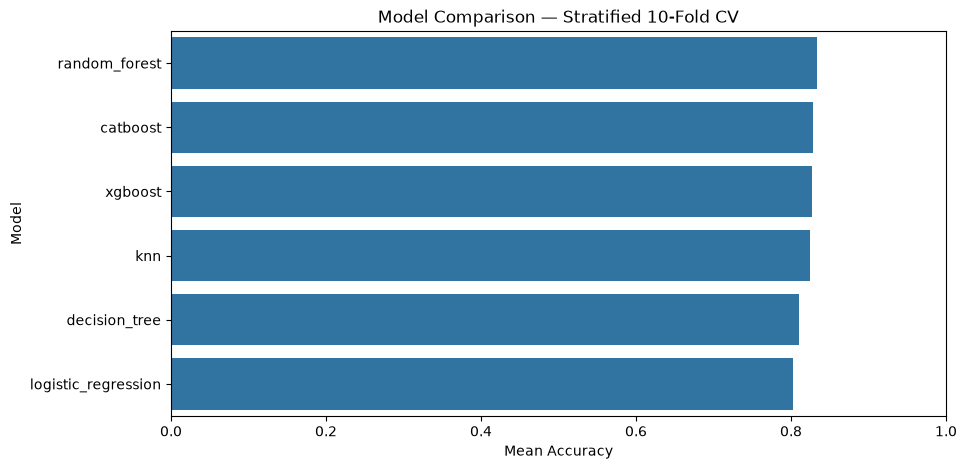

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='CV Mean',
    y='Model',
)

plt.title('Model Comparison — Stratified 10-Fold CV')
plt.xlabel('Mean Accuracy')
plt.ylabel('Model')
plt.xlim(0, 1)
plt.show()

## Deep Learning

In [ ]:
import torch
from dl import prepare_data, MLP, train_model

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=config.split.test_size,
    random_state=config.general.seed,
    stratify=y
)

train_dataset, val_dataset = prepare_data(X_train, X_val, y_train, y_val)

In [ ]:
model = MLP(
    input_dim=train_dataset.tensors[0].shape[1]
).to(device)

best_model_state = train_model(model, train_dataset, val_dataset, device)

model.load_state_dict(best_model_state)

Epoch 1/100 | Train Loss: 0.7004 | Val Loss: 0.6807 | Val Accuracy: 0.5896
Epoch 2/100 | Train Loss: 0.6700 | Val Loss: 0.6531 | Val Accuracy: 0.6604
Epoch 3/100 | Train Loss: 0.6406 | Val Loss: 0.6264 | Val Accuracy: 0.7201
Epoch 4/100 | Train Loss: 0.6115 | Val Loss: 0.5999 | Val Accuracy: 0.7537
Epoch 5/100 | Train Loss: 0.5845 | Val Loss: 0.5745 | Val Accuracy: 0.7649
Epoch 6/100 | Train Loss: 0.5601 | Val Loss: 0.5518 | Val Accuracy: 0.7836
Epoch 7/100 | Train Loss: 0.5393 | Val Loss: 0.5325 | Val Accuracy: 0.8060
Epoch 8/100 | Train Loss: 0.5214 | Val Loss: 0.5156 | Val Accuracy: 0.8172
Epoch 9/100 | Train Loss: 0.5063 | Val Loss: 0.4999 | Val Accuracy: 0.8246
Epoch 10/100 | Train Loss: 0.4934 | Val Loss: 0.4867 | Val Accuracy: 0.8172
Epoch 11/100 | Train Loss: 0.4813 | Val Loss: 0.4752 | Val Accuracy: 0.8060
Epoch 12/100 | Train Loss: 0.4714 | Val Loss: 0.4657 | Val Accuracy: 0.8097
Epoch 13/100 | Train Loss: 0.4630 | Val Loss: 0.4576 | Val Accuracy: 0.8209
Epoch 14/100 | Train 

<All keys matched successfully>